In [1]:
import sys
import os
import json
import numpy as np
import scipy as sp


sys.path.append(os.path.join(os.getcwd(), '../../src/'))
from utils_mouse import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/utils/train_utils.py'>

In [3]:
ll = 'll00'
data_variant = 'gcamp'
model_variant = 'ns'
organism = 'mouse-2019-stringer'

In [4]:
# file_ids = list(range(0, 12+1))
file_ids = [2]

path = os.path.join(read_utils.get_data_path(), '6163622/sessions')
filenames = [read_utils.get_filename(read_utils.get_filepath(path, file_id)) for file_id in file_ids]

In [5]:
manual = False

if manual:
	with open('../../hyperparams_manual.json', 'r') as f:
		reg_lambdas = json.load(f)
else:
	with open('../../hyperparams.json', 'r') as f:
		reg_lambdas = json.load(f)['geometric'][ll]

bom_folder = (f'{data_variant}_bom_{model_variant}_'
			  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['bom'][param]:.2E}' for param in reg_lambdas[model_variant]['bom'].keys()]))
hgm_folder = (f'{data_variant}_hgm_{model_variant}_'
			  + '_'.join([f'{param.split('_')[0]}{reg_lambdas[model_variant]['hgm'][param]:.2E}' for param in reg_lambdas[model_variant]['hgm'].keys()]))

# scores

In [6]:
def assemble(boms_scores_per_neuron, hgms_scores_per_neuron):
	neurons_labels = [scores_per_neuron[0].columns for scores_per_neuron in hgms_scores_per_neuron]

	boms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron = [np.array([split.values[0] for split in scores]) for scores in hgms_scores_per_neuron]

	neuron_scores = dict()
	boms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in boms_scores_per_neuron]
	hgms_scores_per_neuron_avg = [np.mean(scores, axis=0) for scores in hgms_scores_per_neuron]
	for label_list, score_bom_list, score_hgm_list in zip(neurons_labels, boms_scores_per_neuron_avg, hgms_scores_per_neuron_avg):
		sort_indices = np.argsort(score_hgm_list)[::-1]
		label_list = label_list[sort_indices]
		score_bom_list = score_bom_list[sort_indices]
		score_hgm_list = score_hgm_list[sort_indices]

		for i in range(len(label_list)):
			label = label_list[i]
			if label != '' and label[-1] != '_':
				score_bom_new, score_hgm_new = np.array(score_bom_list[i]), np.array(score_hgm_list[i])
				if len(score_hgm_new.shape) == 0:
					score_bom_new = score_bom_new.reshape(1, 1)
					score_hgm_new = score_hgm_new.reshape(1, 1)
				if label not in neuron_scores.keys():
					neuron_scores[label] = (score_bom_new, score_hgm_new)
				else:
					score_bom_prev, score_hgm_prev = neuron_scores[label]
					neuron_scores[label] = (np.vstack([score_bom_prev, score_bom_new]), np.vstack([score_hgm_prev, score_hgm_new]))

	return neuron_scores

In [7]:
boms_spn = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', bom_folder), filename)[0] for filename in filenames]
hgms_spn = [train_utils.load_predictions(os.path.join(read_utils.get_model_path(), 'predictions', hgm_folder), filename)[0] for filename in filenames]

In [8]:
neuron_scores = assemble(boms_spn, hgms_spn)

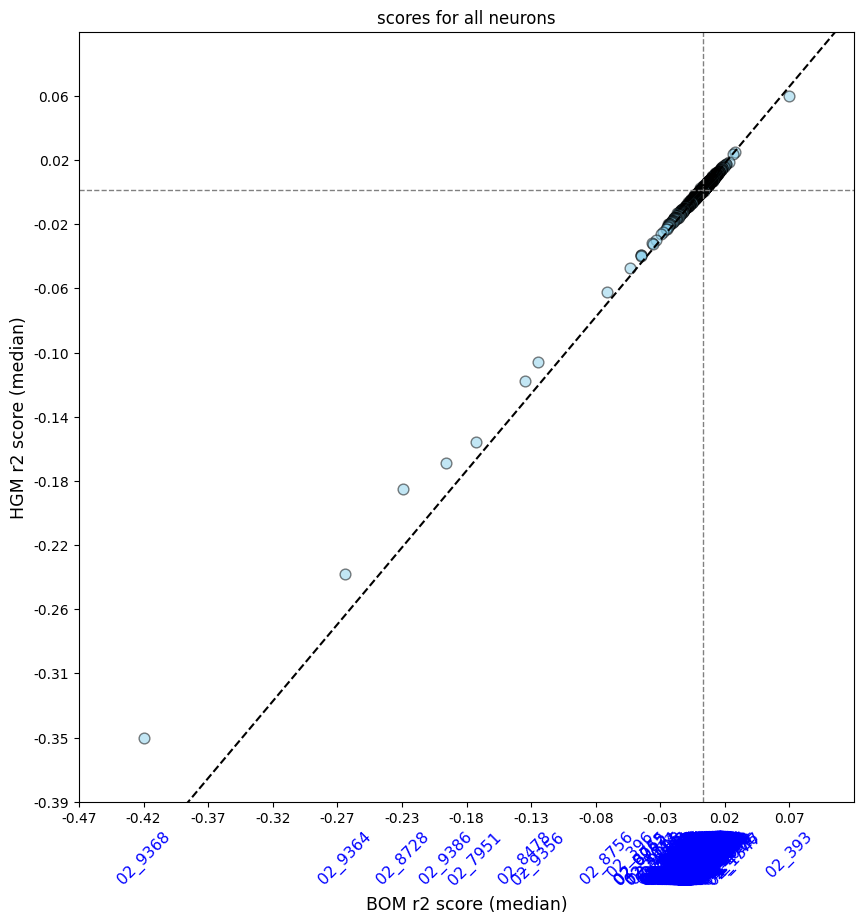

In [9]:
plot_utils.plot_performance_plot(
	neuron_scores, None,
	title='scores for all neurons', limits=None, force_medians=False
)

In [10]:
neuron_scores_hgm_rel = list(reversed(sorted({key: value for key, value in neuron_scores.items() if 0 < np.median(value[0]) < np.median(value[1])}.items(), key=lambda x: np.median(x[1][1]))))
neuron_scores_hgm_rel_labels = list([val[0] for val in neuron_scores_hgm_rel])

print('\n'.join([f'NEURON: {key},\t\tHGMSCR: {np.median(val[1]):.4f}' for key, val in neuron_scores_hgm_rel]))

NEURON: 02_2566,		HGMSCR: 0.0113
NEURON: 02_7854,		HGMSCR: 0.0105
NEURON: 02_3712,		HGMSCR: 0.0103
NEURON: 02_006,		HGMSCR: 0.0099
NEURON: 02_100,		HGMSCR: 0.0099
NEURON: 02_8349,		HGMSCR: 0.0097
NEURON: 02_3754,		HGMSCR: 0.0096
NEURON: 02_4039,		HGMSCR: 0.0094
NEURON: 02_9107,		HGMSCR: 0.0089
NEURON: 02_754,		HGMSCR: 0.0086
NEURON: 02_2314,		HGMSCR: 0.0085
NEURON: 02_008,		HGMSCR: 0.0084
NEURON: 02_048,		HGMSCR: 0.0081
NEURON: 02_2999,		HGMSCR: 0.0081
NEURON: 02_992,		HGMSCR: 0.0077
NEURON: 02_7081,		HGMSCR: 0.0077
NEURON: 02_3278,		HGMSCR: 0.0076
NEURON: 02_8884,		HGMSCR: 0.0074
NEURON: 02_8828,		HGMSCR: 0.0073
NEURON: 02_7884,		HGMSCR: 0.0069
NEURON: 02_2274,		HGMSCR: 0.0069
NEURON: 02_4863,		HGMSCR: 0.0068
NEURON: 02_8324,		HGMSCR: 0.0067
NEURON: 02_1171,		HGMSCR: 0.0067
NEURON: 02_4693,		HGMSCR: 0.0066
NEURON: 02_4916,		HGMSCR: 0.0066
NEURON: 02_4792,		HGMSCR: 0.0066
NEURON: 02_4388,		HGMSCR: 0.0065
NEURON: 02_2323,		HGMSCR: 0.0065
NEURON: 02_7346,		HGMSCR: 0.0064
NEURON: 02_5054,

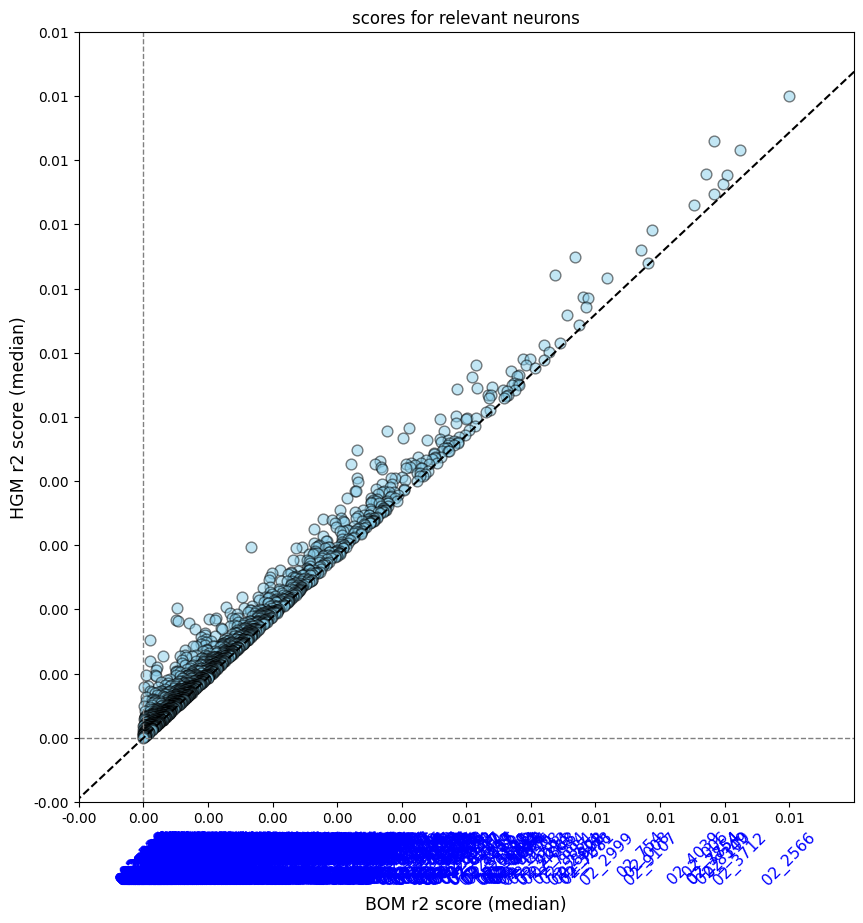

In [11]:
plot_utils.plot_performance_plot(
	{key: neuron_scores[key] for key in neuron_scores_hgm_rel_labels}, None,
	title='scores for relevant neurons', limits=None, force_medians=False
)

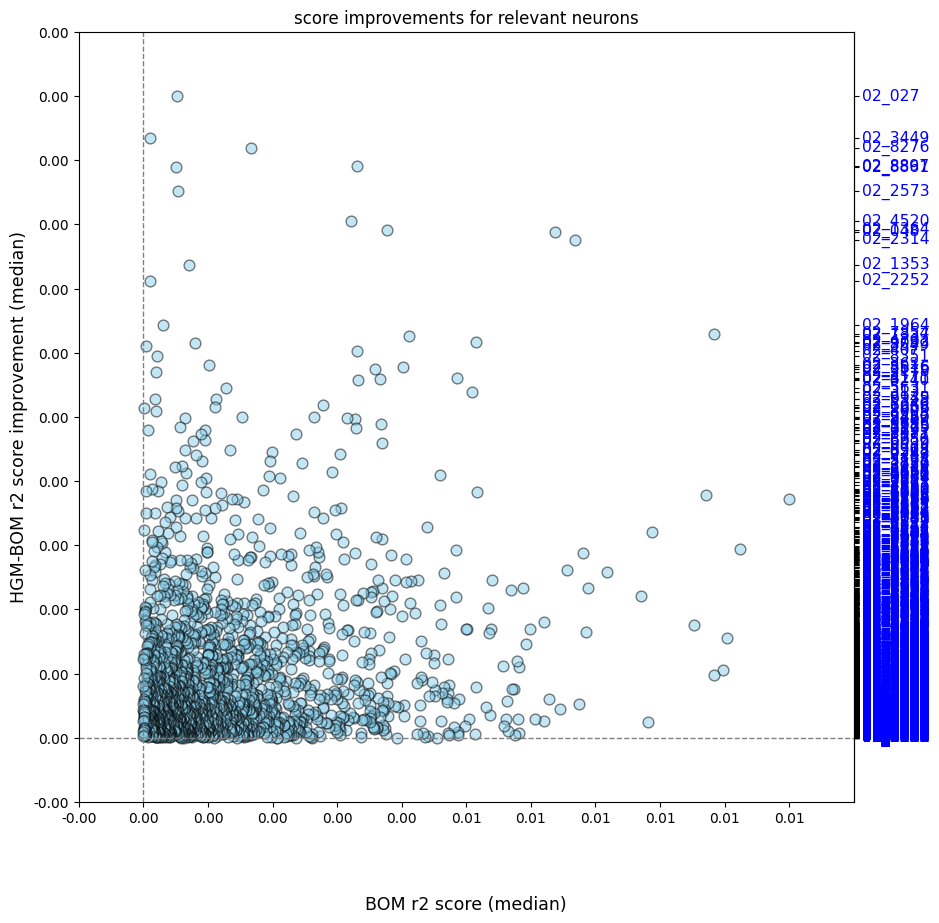

In [12]:
plot_utils.plot_improvement_plot(
	{key: neuron_scores[key] for key in neuron_scores_hgm_rel_labels}, None,
	title='score improvements for relevant neurons', limits=None, force_medians=False
)

In [13]:
neuron_impros_hgm_rel = list(reversed(sorted(neuron_scores_hgm_rel, key=lambda x: np.median(x[1][1] - x[1][0]))))
neuron_impros_hgm_rel_labels = list([val[0] for val in neuron_impros_hgm_rel])

print('\n'.join([f'NEURON: {key},\t\tIMPR: {np.median(val[1] - val[0]):.4f}' for key, val in neuron_impros_hgm_rel]))

NEURON: 02_027,		IMPR: 0.0017
NEURON: 02_3449,		IMPR: 0.0016
NEURON: 02_8276,		IMPR: 0.0016
NEURON: 02_8897,		IMPR: 0.0015
NEURON: 02_8861,		IMPR: 0.0015
NEURON: 02_2573,		IMPR: 0.0015
NEURON: 02_4520,		IMPR: 0.0014
NEURON: 02_1364,		IMPR: 0.0014
NEURON: 02_048,		IMPR: 0.0014
NEURON: 02_2314,		IMPR: 0.0013
NEURON: 02_1353,		IMPR: 0.0013
NEURON: 02_2252,		IMPR: 0.0012
NEURON: 02_1964,		IMPR: 0.0011
NEURON: 02_7854,		IMPR: 0.0011
NEURON: 02_1337,		IMPR: 0.0011
NEURON: 02_4792,		IMPR: 0.0011
NEURON: 02_9093,		IMPR: 0.0011
NEURON: 02_8549,		IMPR: 0.0011
NEURON: 02_407,		IMPR: 0.0010
NEURON: 02_8351,		IMPR: 0.0010
NEURON: 02_362,		IMPR: 0.0010
NEURON: 02_8516,		IMPR: 0.0010
NEURON: 02_5616,		IMPR: 0.0010
NEURON: 02_3178,		IMPR: 0.0010
NEURON: 02_317,		IMPR: 0.0010
NEURON: 02_4111,		IMPR: 0.0010
NEURON: 02_8240,		IMPR: 0.0010
NEURON: 02_5631,		IMPR: 0.0009
NEURON: 02_313,		IMPR: 0.0009
NEURON: 02_9139,		IMPR: 0.0009
NEURON: 02_6945,		IMPR: 0.0009
NEURON: 02_5340,		IMPR: 0.0009
NEURON: 02_606

In [14]:
print('Neuron names for copying:')
print(', '.join([f'\'{label}\'' for label in neuron_impros_hgm_rel_labels]))

Neuron names for copying:
'02_027', '02_3449', '02_8276', '02_8897', '02_8861', '02_2573', '02_4520', '02_1364', '02_048', '02_2314', '02_1353', '02_2252', '02_1964', '02_7854', '02_1337', '02_4792', '02_9093', '02_8549', '02_407', '02_8351', '02_362', '02_8516', '02_5616', '02_3178', '02_317', '02_4111', '02_8240', '02_5631', '02_313', '02_9139', '02_6945', '02_5340', '02_6068', '02_1656', '02_8605', '02_926', '02_2320', '02_2452', '02_542', '02_5249', '02_9296', '02_1973', '02_5125', '02_059', '02_329', '02_3171', '02_7977', '02_8286', '02_6952', '02_6939', '02_3918', '02_030', '02_8228', '02_9247', '02_2253', '02_5728', '02_3197', '02_2822', '02_3259', '02_8979', '02_6667', '02_4279', '02_1691', '02_8070', '02_9381', '02_9360', '02_9154', '02_9011', '02_2871', '02_4397', '02_7100', '02_4512', '02_1063', '02_863', '02_770', '02_8510', '02_6662', '02_006', '02_6276', '02_4554', '02_4293', '02_2566', '02_6267', '02_8535', '02_017', '02_5005', '02_4168', '02_773', '02_1437', '02_9027', 